<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Semana 08: Árboles, ensambles y validación cruzada</p>
</div>
</div>

# 08 · Árboles, ensambles y validación cruzada

> **La pregunta de hoy:** si cobranza cambia la logística por un bosque, ¿cómo sabemos que es mejor y
> no la suerte de una partición?

Tres tiempos: **yo lo hago** (el árbol y su inestabilidad, medida), **lo hacemos juntos** (validación
cruzada, curva en U y búsqueda) y **lo hacen ustedes** (elegir entre cuatro modelos y defenderlo).

## Preparación del entorno

En Colab estas librerías ya vienen instaladas; la celda queda para correr fuera de Colab. La siguiente
define `num`, que escribe las cifras con punto de miles y coma decimal.

In [1]:
%%capture
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
from IPython.display import Markdown, display  # muestra frases con las cifras ya calculadas

def num(x, dec=0):
    # miles con punto, decimales con coma y el menos tipográfico
    texto = f'{x:,.{dec}f}'.replace(',', '@').replace('.', ',').replace('@', '.')
    return texto.replace('-', '−')

## Cargar datos

La cartera de cobranza de **tarjetas de crédito**, `riesgo_impago.csv`, leída con **pandas**.

<!-- contrato: accion=fijar-base -->

In [3]:
import os                # revisa si el archivo está en una carpeta local
import pandas as pd      # la librería de tablas: lee el archivo y lo deja como DataFrame

REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

datos = pd.read_csv(BASE + 'riesgo_impago.csv')
print('registros y columnas:', datos.shape)
datos.head()

registros y columnas: (6000, 16)


,id_cliente,edad,nivel_educacion,limite_credito,meses_mora,meses_mora_previo,meses_mora_acumulados,monto_facturado_mes,monto_facturado_mes_anterior,monto_facturado_dos_meses_antes,monto_pagado_mes,monto_pagado_mes_anterior,monto_pagado_dos_meses_antes,uso_credito,cobertura_pago,incumplio_pago
0,R-0001,34,universitaria,90000,0,0,0,29239,14027,13559,1518,1500,1000,0.3249,0.0519,no
1,R-0002,37,posgrado,50000,0,0,0,64400,57069,57608,2500,1815,657,1.2880,0.0388,no
2,R-0003,29,posgrado,250000,0,0,0,70887,67060,63561,3000,3000,3000,0.2835,0.0423,no
3,R-0004,26,universitaria,70000,2,0,6,41087,42445,45020,2007,3582,0,0.5870,0.0488,si
4,R-0005,47,media,50000,0,0,0,650,3415,3416,3415,3421,2044,0.0130,3.0000,no


## El encuadre, antes de medir nada

- **Unidad de observación:** un registro es un **cliente observado en un mes**.
- **Objetivo:** si el cliente **incumple el pago del mes siguiente** (`incumplio_pago`, `si` o `no`).
- **Clase positiva:** **incumplir**, el evento que interesa detectar.
- **Métrica:** **ROC-AUC**, que resume qué tan bien ordena el modelo a los clientes, de 0,5 (al azar)
  a 1 (perfecto).

La celda codifica el objetivo (1 = incumple, 0 = paga) y deja como predictoras todas las columnas
menos `id_cliente` y el objetivo.

<!-- contrato: accion=declarar-positiva -->

In [4]:
y = datos['incumplio_pago'].map({'no': 0, 'si': 1})  # 1 = incumple, la clase positiva

# nivel_educacion es la única categórica: se prepara distinto que las numéricas
COLUMNAS_CAT = ['nivel_educacion']
COLUMNAS_NUM = []
for columna in datos.columns:  # todas menos el identificador, el objetivo y la categórica
    if columna not in ['id_cliente', 'incumplio_pago'] + COLUMNAS_CAT:
        COLUMNAS_NUM.append(columna)
X = datos[COLUMNAS_NUM + COLUMNAS_CAT]

display(Markdown(
    f'Quedan **{len(COLUMNAS_NUM)}** predictoras numéricas y **{len(COLUMNAS_CAT)}** categórica.'
))

Quedan **13** predictoras numéricas y **1** categórica.

### La partición: 60 / 20 / 20, estratificada

Es la de la sesión 7, con la misma semilla (`random_state=42`) y estratificada por el objetivo
(`stratify=y`). Prueba se aparta y no se vuelve a tocar hasta la actividad. Hoy importa además el
pedazo intermedio:

- `X_trainval`: **entrenamiento y validación juntos**. Es donde rotan los pliegues de la validación
  cruzada.
- `X_train` y `X_val`: la partición fija de entrenamiento y validación, que usamos para las
  demostraciones previas a los pliegues.

<!-- contrato: accion=partir -->

In [5]:
from sklearn.model_selection import train_test_split  # sortea la partición

# 20 % a prueba, y del resto un 25 % a validación: quedan 60 / 20 / 20
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval)
pruebas_abiertas = []   # para qué modelo se abre prueba: se llena una sola vez, en la actividad

display(Markdown(
    f'Entrenamiento: **{num(len(X_train))}** · validación: **{num(len(X_val))}** · prueba: '
    f'**{num(len(datos) - len(X_trainval))}**, guardada hasta la actividad. Entrenamiento y validación '
    f'juntos, `X_trainval`: **{num(len(X_trainval))}** clientes.'
))

Entrenamiento: **3.600** · validación: **1.200** · prueba: **1.200**, guardada hasta la actividad. Entrenamiento y validación juntos, `X_trainval`: **4.800** clientes.

# Tiempo 1 · Yo lo hago

## Un árbol de dos preguntas: `DecisionTreeClassifier`

Un **árbol de decisión** predice con preguntas de sí o no encadenadas, cada una sobre una columna.
`DecisionTreeClassifier` aprende de los datos qué preguntar y con qué valor; `max_depth=2` lo limita a
dos preguntas encadenadas.

La preparación va **sin escalar** (`'passthrough'`): una pregunta como «¿2 o más meses de mora?» da lo
mismo en cualquier escala, y así el árbol muestra los valores en unidades del archivo. Se define una vez,
y cada pipeline recibe una copia nueva con `clone`, para que entrenar uno no cambie a otro.

<!-- contrato: accion=arbol-dos -->

In [6]:
from sklearn.pipeline import Pipeline             # encadena la preparación y el modelo
from sklearn.compose import ColumnTransformer     # prepara cada grupo de columnas a su manera
from sklearn.preprocessing import OneHotEncoder   # convierte una categórica en columnas de 0 y 1
from sklearn.base import clone                    # copia sin entrenar de una preparación
from sklearn.tree import DecisionTreeClassifier   # el árbol de decisión

preparar_arbol = ColumnTransformer([
    ('num', 'passthrough', COLUMNAS_NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), COLUMNAS_CAT),
], verbose_feature_names_out=False)  # nombres de columna sin prefijo, para leer el árbol

arbol_2 = Pipeline([('preparar', clone(preparar_arbol)),
                    ('modelo', DecisionTreeClassifier(max_depth=2, random_state=42))])
arbol_2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['edad','limite_credito','meses_mora',...,'uso_credito','cobertura_pago', 'nivel_educacion']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equiva

### El árbol, dibujado con `plot_tree`

`plot_tree` recibe el árbol ajustado —el paso `modelo` del pipeline— y los nombres de las columnas que
salen de la preparación. Cada caja muestra la pregunta, cuántos clientes llegan (`samples`) y cuántos
de cada clase (`value`); el color se intensifica hacia la clase que predice. Se lee de arriba abajo:
`meses_mora <= 1.5` es «¿1 mes de mora o menos?», y si la respuesta es sí se va a la izquierda. Cada
hoja predice la **proporción que incumplió** en su grupo de entrenamiento; debajo, tres clientes de
validación la recorren.

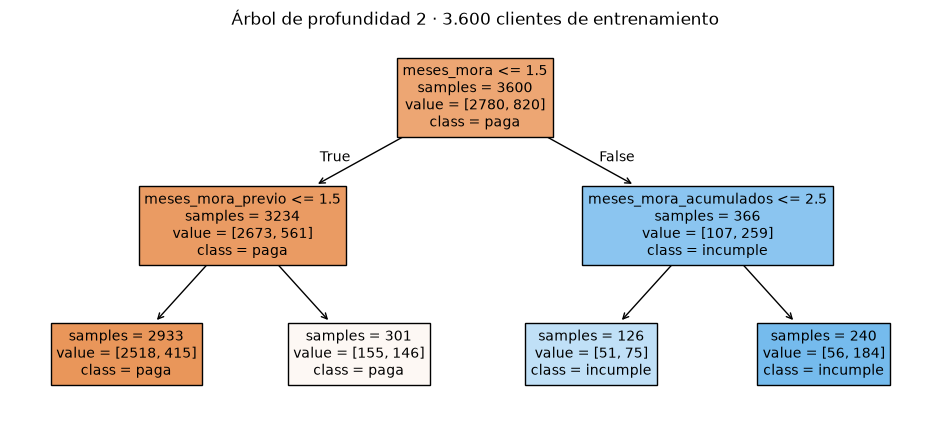

In [7]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree   # dibuja un árbol ajustado

nombres = arbol_2.named_steps['preparar'].get_feature_names_out()
plt.figure(figsize=(12, 5))
plot_tree(arbol_2.named_steps['modelo'], feature_names=list(nombres),
          class_names=['paga', 'incumple'], filled=True, impurity=False, fontsize=10)
plt.title(f'Árbol de profundidad 2 · {num(len(X_train))} clientes de entrenamiento')
plt.show()

In [8]:
tres = ['R-4608', 'R-5805', 'R-2647']   # un cliente por hoja distinta
en_validacion = datos.loc[X_val.index]
marcados = en_validacion['id_cliente'].isin(tres).to_numpy()
tabla = en_validacion.loc[marcados, ['id_cliente', 'meses_mora', 'meses_mora_previo',
                                     'meses_mora_acumulados', 'incumplio_pago']]
tabla['probabilidad del árbol'] = arbol_2.predict_proba(X_val[marcados])[:, 1].round(2)
tabla

,id_cliente,meses_mora,meses_mora_previo,meses_mora_acumulados,incumplio_pago,probabilidad del árbol
4607,R-4608,0,0,0,no,0.14
5804,R-5805,2,2,2,si,0.60
2646,R-2647,1,2,4,si,0.49


## Sin límite, el árbol memoriza

Sin `max_depth`, el árbol sigue preguntando hasta que casi cada hoja tiene un solo tipo de cliente.
`get_n_leaves` cuenta sus hojas, y `roc_auc_score` lo mide en entrenamiento y en
validación.

<!-- contrato: accion=arbol-libre -->

In [9]:
from sklearn.metrics import roc_auc_score   # recibe lo observado y la probabilidad

arbol_libre = Pipeline([('preparar', clone(preparar_arbol)),
                        ('modelo', DecisionTreeClassifier(random_state=42))])
arbol_libre.fit(X_train, y_train)
auc_train = roc_auc_score(y_train, arbol_libre.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, arbol_libre.predict_proba(X_val)[:, 1])
display(Markdown(
    f'**{num(arbol_libre.named_steps["modelo"].get_n_leaves())} hojas**. ROC-AUC: **{num(auc_train, 2)}** '
    f'en entrenamiento y **{num(auc_val, 2)}** en validación. Ordena perfecto a quienes vio y apenas '
    f'mejor que el azar a quienes no.'
))

**612 hojas**. ROC-AUC: **1,00** en entrenamiento y **0,61** en validación. Ordena perfecto a quienes vio y apenas mejor que el azar a quienes no.

## La inestabilidad, medida: árbol contra bosque

Un **random forest** (bosque aleatorio) entrena muchos árboles, cada uno con una **remuestra** distinta
de los clientes de entrenamiento y eligiendo cada pregunta entre **algunas columnas sorteadas**, y
promedia las probabilidades que entregan. `RandomForestClassifier` lo hace con 100 árboles por defecto; `n_jobs=-1` usa todos los
núcleos del computador.

El experimento separa las **dos variaciones** de la clase:

1. Se apartan **600 clientes de referencia** de `X_trainval`. No entran a ningún entrenamiento ni
   validación de este experimento: solo se mira qué predice cada modelo para ellos.
2. Con los demás se arman **20 particiones** distintas, y en cada una se entrena un árbol sin límite y
   un bosque. El ciclo tarda unos segundos y guarda, por modelo, lo que predice para los clientes de
   referencia y su ROC-AUC de validación.

Después se miran las dos variaciones por separado. **La del modelo:** un cliente de referencia
**cambia de clase** si, con el umbral de 0,5, queda de un lado en alguna partición y del otro en otra;
NumPy lo cuenta con `any` y `all` sobre la tabla de 20 × 600 predicciones. Después, la de la
evaluación.

<!-- contrato: accion=grupo-referencia -->
<!-- contrato: accion=veinte-particiones -->

In [10]:
from sklearn.ensemble import RandomForestClassifier   # el bosque aleatorio

X_resto, X_ref, y_resto, y_ref = train_test_split(   # los 600 de referencia quedan fuera del ciclo
    X_trainval, y_trainval, test_size=600, random_state=42, stratify=y_trainval)
pred_arbol, pred_bosque, auc_arbol, auc_bosque = [], [], [], []
for semilla in range(20):  # cada semilla arma una partición distinta de entrenamiento y validación
    X_train_semilla, X_val_semilla, y_train_semilla, y_val_semilla = train_test_split(
        X_resto, y_resto, test_size=0.25, random_state=semilla, stratify=y_resto)
    arbol = Pipeline([('preparar', clone(preparar_arbol)), ('modelo', DecisionTreeClassifier(random_state=42))])
    bosque = Pipeline([('preparar', clone(preparar_arbol)),
                       ('modelo', RandomForestClassifier(random_state=42, n_jobs=-1))])
    arbol.fit(X_train_semilla, y_train_semilla)
    bosque.fit(X_train_semilla, y_train_semilla)
    pred_arbol.append(arbol.predict_proba(X_ref)[:, 1])
    pred_bosque.append(bosque.predict_proba(X_ref)[:, 1])
    auc_arbol.append(roc_auc_score(y_val_semilla, arbol.predict_proba(X_val_semilla)[:, 1]))
    auc_bosque.append(roc_auc_score(y_val_semilla, bosque.predict_proba(X_val_semilla)[:, 1]))

In [11]:
import numpy as np  # cálculo numérico: acá, contar sobre la tabla de predicciones

def cambian_de_clase(predicciones):
    sobre_umbral = np.array(predicciones) >= 0.5      # 20 particiones × 600 clientes
    alguna, todas = sobre_umbral.any(axis=0), sobre_umbral.all(axis=0)
    return (alguna & ~todas).mean()                   # alguna vez sí y alguna vez no

cambia_arbol, cambia_bosque = cambian_de_clase(pred_arbol), cambian_de_clase(pred_bosque)
display(Markdown(
    f'Cambian de clase según la partición: **{num(100 * cambia_arbol)} %** de los clientes con el árbol '
    f'sin límite y **{num(100 * cambia_bosque)} %** con el bosque.'
))

Cambian de clase según la partición: **79 %** de los clientes con el árbol sin límite y **17 %** con el bosque.

**La de la evaluación:** cuánto se mueve la cifra de validación de cada modelo entre las mismas 20
particiones.

In [12]:
cifras = pd.DataFrame({'árbol sin límite': auc_arbol, 'bosque': auc_bosque})
resumen = pd.DataFrame({'media': cifras.mean(), 'mínimo': cifras.min(), 'máximo': cifras.max()})
resumen['rango'] = resumen['máximo'] - resumen['mínimo']
display(resumen.round(2))
display(Markdown(
    f'El bosque está más arriba, pero su cifra se mueve casi lo mismo: un rango de '
    f'**{num(resumen.loc["bosque", "rango"], 2)}** contra **{num(resumen.loc["árbol sin límite", "rango"], 2)}**.'
))

,media,mínimo,máximo,rango
árbol sin límite,0.62,0.57,0.65,0.08
bosque,0.76,0.73,0.80,0.07


El bosque está más arriba, pero su cifra se mueve casi lo mismo: un rango de **0,07** contra **0,08**.

### Dos variaciones, dos remedios

<p align="center"></p>

| Fuente de variación | Efecto observable | Solución metodológica |
|:--|:--|:--|
| **El modelo** | con otra muestra, otra predicción para el mismo cliente | el **bosque** |
| **La evaluación** | con otra partición, otra cifra para el mismo modelo | la **validación cruzada** |

El bosque no vuelve confiable la cifra de una partición. Para resolver esa segunda variación se utiliza la validación cruzada en el Tiempo 2.

# Tiempo 2 · Lo hacemos juntos

## La validación cruzada: `StratifiedKFold` y `cross_val_score`

`StratifiedKFold` reparte `X_trainval` en **5 pliegues** con la misma proporción de impagos cada uno;
`shuffle=True` mezcla antes de repartir. `cross_val_score` recibe el pipeline, los datos, los
pliegues y la métrica: en cada ronda entrena con cuatro pliegues, valida con el quinto, y devuelve las
cinco cifras. Calcula de nuevo la preparación en cada ronda, así que no hay fuga.

<p align="center"></p>

Empezamos por la **regresión logística**, con su pipeline de preparación. La desviación entre pliegues es
**orientativa**: los cinco entrenamientos comparten casi todos sus clientes, así que sirve para comparar
modelos con los **mismos** pliegues, no para demostrar que difieren.

<!-- contrato: accion=validar-cruzado -->

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score  # los pliegues y su evaluación
from sklearn.preprocessing import StandardScaler     # deja cada numérica con promedio 0 y desviación 1
from sklearn.linear_model import LogisticRegression  # la regresión logística

pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logistica = Pipeline([
    ('preparar', ColumnTransformer([('num', StandardScaler(), COLUMNAS_NUM),
                                    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), COLUMNAS_CAT)])),
    ('modelo', LogisticRegression(max_iter=2000)),
])
cv_logistica = cross_val_score(logistica, X_trainval, y_trainval, cv=pliegues, scoring='roc_auc')
display(Markdown(
    f'Cinco cifras, de {num(cv_logistica.min(), 3)} a {num(cv_logistica.max(), 3)}. Se informan la '
    f'**media, {num(cv_logistica.mean(), 3)}**, y la '
    f'**desviación, {num(cv_logistica.std(), 3)}**, que dice cuánto se movió la cifra entre pliegues.'
))

Cinco cifras, de 0,746 a 0,776. Se informan la **media, 0,754**, y la **desviación, 0,011**, que dice cuánto se movió la cifra entre pliegues.

## La curva en U, con `validation_curve`

`validation_curve` hace la validación cruzada para cada valor de **un** hiperparámetro y devuelve dos
tablas: el puntaje de entrenamiento y el de validación, una fila por valor y una columna por pliegue.
`param_name` dice qué hiperparámetro mover —el paso `modelo`, dos guiones bajos y su nombre— y
`param_range`, qué valores probar; `None` es «sin límite».

<!-- contrato: accion=curva-u -->

In [14]:
from sklearn.model_selection import validation_curve  # validación cruzada para cada valor de un hiperparámetro

PROFUNDIDADES = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, None]
arbol = Pipeline([('preparar', clone(preparar_arbol)), ('modelo', DecisionTreeClassifier(random_state=42))])
puntaje_train, puntaje_val = validation_curve(
    arbol, X_trainval, y_trainval, param_name='modelo__max_depth', param_range=PROFUNDIDADES,
    cv=pliegues, scoring='roc_auc')
curva = pd.DataFrame({'entrenamiento': puntaje_train.mean(axis=1), 'validación': puntaje_val.mean(axis=1)},
                     index=PROFUNDIDADES)

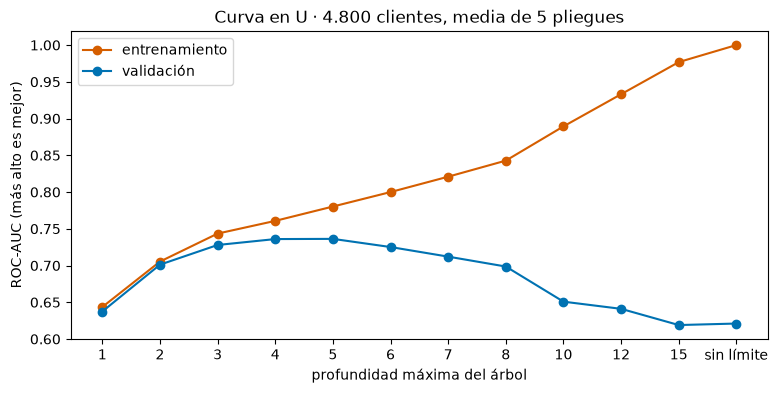

Entrenamiento sube siempre, hasta **1,00** sin límite. Validación llega a su punto más alto con profundidad **5** (0,736), casi empatada con **4** (0,736), y cae a **0,621** sin límite. Más alto es mejor: la U se ve al revés.

In [15]:
rotulos = []
for p in PROFUNDIDADES:
    rotulos.append('sin límite' if p is None else str(p))
ax = curva.plot(marker='o', figsize=(9, 4), color=['#D55E00', '#0072B2'], xticks=range(len(rotulos)),
                use_index=False, title=f'Curva en U · {num(len(X_trainval))} clientes, media de 5 pliegues')
ax.set_xticklabels(rotulos)
ax.set(xlabel='profundidad máxima del árbol', ylabel='ROC-AUC (más alto es mejor)')
plt.show()

orden = np.argsort(curva['validación'].to_numpy())   # de la peor a la mejor profundidad
mejor, segunda = rotulos[orden[-1]], rotulos[orden[-2]]  # el rótulo: None se vuelve «sin límite»
display(Markdown(
    f'Entrenamiento sube siempre, hasta **{num(curva["entrenamiento"].iloc[-1], 2)}** sin límite. '
    f'Validación llega a su punto más alto con profundidad **{mejor}** ({num(curva["validación"].max(), 3)}), '
    f'casi empatada con **{segunda}** ({num(curva["validación"].iloc[orden[-2]], 3)}), y cae a '
    f'**{num(curva["validación"].iloc[-1], 3)}** sin límite. Más alto es mejor: la U se ve al revés.'
))

## La búsqueda: `GridSearchCV`

`GridSearchCV` automatiza la búsqueda de hiperparámetros: recibe el pipeline y una **grilla**, prueba
**cada combinación** con los pliegues y la métrica, y al final **vuelve a entrenar la mejor** con todo
`X_trainval`. Dos hiperparámetros del árbol: la profundidad y el mínimo de clientes por hoja
(`min_samples_leaf`), que prohíbe hojas más chicas.

<!-- contrato: accion=buscar-arbol -->

In [16]:
from sklearn.model_selection import GridSearchCV  # prueba cada combinación de la grilla con los pliegues

grilla_arbol = {'modelo__max_depth': [3, 5, 8, None], 'modelo__min_samples_leaf': [1, 20, 100]}
busqueda_arbol = GridSearchCV(arbol, grilla_arbol, cv=pliegues, scoring='roc_auc')
busqueda_arbol.fit(X_trainval, y_trainval)
combinaciones = len(grilla_arbol['modelo__max_depth']) * len(grilla_arbol['modelo__min_samples_leaf'])
display(Markdown(f'{combinaciones} combinaciones × 5 pliegues = **{combinaciones * 5} entrenamientos**, '
                 f'y uno más para volver a entrenar la mejor.'))

12 combinaciones × 5 pliegues = **60 entrenamientos**, y uno más para volver a entrenar la mejor.

### Todos los intentos: `cv_results_`

`cv_results_` guarda **cada intento**, no solo el ganador: sus hiperparámetros, la media y la desviación
de los pliegues, y su lugar. Se ordena por `rank_test_score`, el lugar, con 1 para el mejor.

In [17]:
intentos = pd.DataFrame(busqueda_arbol.cv_results_)
intentos = intentos[['param_modelo__max_depth', 'param_modelo__min_samples_leaf',
                     'mean_test_score', 'std_test_score', 'rank_test_score']]
intentos = intentos.sort_values('rank_test_score')
display(intentos.round(3))

ganador = intentos.iloc[0]
banda = ganador['mean_test_score'] - ganador['std_test_score']
empatados = (intentos['mean_test_score'] >= banda).sum()
display(Markdown(
    f'Gana **{num(ganador["mean_test_score"], 3)} ± {num(ganador["std_test_score"], 3)}**, pero '
    f'**{empatados}** intentos, contando al ganador, quedan a menos de una desviación de él: con estos '
    f'pliegues, no se distinguen. Entre los empatados conviene el más simple; es una heurística, no una demostración.'
))

,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
11,None,100,0.759,0.014,1
8,8,100,0.757,0.011,2
5,5,100,0.755,0.012,3
4,5,20,0.744,0.012,4
3,5,1,0.736,0.011,5
2,3,100,0.731,0.011,6
7,8,20,0.730,0.021,7
1,3,20,0.730,0.010,8
0,3,1,0.728,0.013,9
10,None,20,0.711,0.017,10


Gana **0,759 ± 0,014**, pero **3** intentos, contando al ganador, quedan a menos de una desviación de él: con estos pliegues, no se distinguen. Entre los empatados conviene el más simple; es una heurística, no una demostración.

# Tiempo 3 · Lo hacen ustedes

## La actividad: ¿bosque, boosting, árbol o logística?

Cobranza evalúa cambiar la logística por un modelo de árboles. Tienen cuatro candidatos: la
**regresión logística**, el **árbol** que eligió la búsqueda, y un **bosque** y un **boosting** que
van a ajustar ustedes.

1. **Cuenten** cuántos entrenamientos costarán las dos grillas, **antes** de correrlas.
2. **Corran la búsqueda del bosque** y lean `cv_results_` completo.
3. **Corran la búsqueda del boosting**, con la misma lectura.
4. **Comparen los cuatro con los mismos pliegues**: media, desviación y en cuántos pliegues le gana cada
   uno a la logística.
5. **Elijan uno y abran prueba una sola vez** para ese modelo.
6. **Defiendan su elección en tres líneas.**

**Criterio de éxito:** la defensa cita la media **y** la desviación de los candidatos, dice si la diferencia
es mayor que la desviación, y pesa lo que se pierde al no poder leer el modelo como reglas.

**Evidencia observable:** la cuenta de entrenamientos, la tabla de comparación y las tres líneas; el
**feedback formativo** llega en la puesta en común.

### Paso 1 · Contar antes de correr

Dos hiperparámetros del bosque: cuántas columnas puede sortear en cada pregunta (`max_features`:
`'sqrt'` es la raíz cuadrada del total; `0.5`, la mitad) y el mínimo de clientes por hoja. Dos del
boosting: cuánto pesa la corrección de cada árbol nuevo (`learning_rate`) y la profundidad de cada árbol. Antes
de ejecutar la celda, hagan la cuenta a mano.

<!-- contrato: accion=contar-ajustes -->

In [18]:
grilla_bosque = {'modelo__max_features': ['sqrt', 0.5], 'modelo__min_samples_leaf': [1, 5, 20, 50]}
combinaciones_bosque = len(grilla_bosque['modelo__max_features']) * len(grilla_bosque['modelo__min_samples_leaf'])
ajustes_bosque = combinaciones_bosque * 5
grilla_boosting = {'modelo__learning_rate': [0.03, 0.1], 'modelo__max_depth': [3, None]}
combinaciones_boosting = len(grilla_boosting['modelo__learning_rate']) * len(grilla_boosting['modelo__max_depth'])
display(Markdown(f'Bosque: {combinaciones_bosque} combinaciones × 5 pliegues = **{ajustes_bosque} entrenamientos**. '
                 f'Boosting: {combinaciones_boosting} × 5 = **{combinaciones_boosting * 5} entrenamientos**. '
                 f'Cada búsqueda suma uno para volver a entrenar a su ganador.'))

Bosque: 8 combinaciones × 5 pliegues = **40 entrenamientos**. Boosting: 4 × 5 = **20 entrenamientos**. Cada búsqueda suma uno para volver a entrenar a su ganador.

### Paso 2 · La búsqueda del bosque

Tarda un poco más que la del árbol: cada ajuste son 100 árboles.

<!-- contrato: accion=buscar-bosque -->

In [19]:
bosque = Pipeline([('preparar', clone(preparar_arbol)),
                   ('modelo', RandomForestClassifier(random_state=42, n_jobs=-1))])
busqueda_bosque = GridSearchCV(bosque, grilla_bosque, cv=pliegues, scoring='roc_auc')
busqueda_bosque.fit(X_trainval, y_trainval)

intentos_bosque = pd.DataFrame(busqueda_bosque.cv_results_)
intentos_bosque = intentos_bosque[['param_modelo__max_features', 'param_modelo__min_samples_leaf',
                                   'mean_test_score', 'std_test_score', 'rank_test_score']]
intentos_bosque.sort_values('rank_test_score').round(3)

,param_modelo__max_features,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
2,sqrt,20,0.777,0.015,1
3,sqrt,50,0.776,0.015,2
7,0.5,50,0.775,0.013,3
6,0.5,20,0.775,0.013,4
1,sqrt,5,0.770,0.020,5
5,0.5,5,0.766,0.017,6
0,sqrt,1,0.758,0.020,7
4,0.5,1,0.751,0.019,8


### Paso 3 · La búsqueda del boosting: `HistGradientBoostingClassifier`

El **gradient boosting** también combina árboles, pero no en paralelo como el bosque: los entrena **en
secuencia**, y cada árbol corrige lo que los anteriores todavía predicen mal. `HistGradientBoostingClassifier`
es la versión de scikit-learn: agrupa los valores de cada columna en intervalos antes de buscar las
preguntas, lo que la hace mucho más rápida cuando hay muchos datos. Su mecanismo no se desarrolla;
acá entra como un candidato más, con su grilla. Una diferencia con el bosque que sí conviene saber: el
boosting **puede sobreajustar** si se le agregan demasiados árboles.

<p align="center"></p>

<!-- contrato: accion=buscar-boosting -->

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier   # árboles en secuencia

boosting = Pipeline([('preparar', clone(preparar_arbol)),
                     ('modelo', HistGradientBoostingClassifier(random_state=42))])
busqueda_boosting = GridSearchCV(boosting, grilla_boosting, cv=pliegues, scoring='roc_auc')
busqueda_boosting.fit(X_trainval, y_trainval)

intentos_boosting = pd.DataFrame(busqueda_boosting.cv_results_)
intentos_boosting = intentos_boosting[['param_modelo__learning_rate', 'param_modelo__max_depth',
                                       'mean_test_score', 'std_test_score', 'rank_test_score']]
intentos_boosting.sort_values('rank_test_score').round(3)

,param_modelo__learning_rate,param_modelo__max_depth,mean_test_score,std_test_score,rank_test_score
0,0.03,3,0.775,0.012,1
2,0.10,3,0.774,0.012,2
1,0.03,None,0.768,0.011,3
3,0.10,None,0.756,0.014,4


### Paso 4 · Los cuatro, con los mismos pliegues

Las cinco cifras del ganador de cada búsqueda están en `cv_results_`, en las columnas `split0_test_score`
a `split4_test_score`, fila `best_index_`. Se suma el **bosque por defecto**, sin ajustar, para ver qué
aporta la búsqueda.

<!-- contrato: accion=comparar -->

In [21]:
def cifras_del_ganador(busqueda):
    cifras = []
    for k in range(5):  # una cifra por pliegue, la del ganador
        cifras.append(busqueda.cv_results_[f'split{k}_test_score'][busqueda.best_index_])
    return np.array(cifras)

cv_bosque_defecto = cross_val_score(bosque, X_trainval, y_trainval, cv=pliegues, scoring='roc_auc')
comparacion = pd.DataFrame({'logística': cv_logistica,
                            'árbol ajustado': cifras_del_ganador(busqueda_arbol),
                            'bosque por defecto': cv_bosque_defecto,
                            'bosque ajustado': cifras_del_ganador(busqueda_bosque),
                            'boosting ajustado': cifras_del_ganador(busqueda_boosting)})
comparacion.round(3)

,logística,árbol ajustado,bosque por defecto,bosque ajustado,boosting ajustado
0,0.747,0.771,0.770,0.780,0.760
1,0.749,0.764,0.777,0.790,0.778
2,0.746,0.740,0.723,0.748,0.763
3,0.776,0.775,0.746,0.781,0.792
4,0.751,0.746,0.773,0.788,0.782


In [22]:
tabla_final = pd.DataFrame({'media': comparacion.mean(),
                            'desviación': comparacion.std(ddof=0)})   # ddof=0: la misma desviación de cv_results_
tabla_final['le gana a la logística en'] = comparacion.gt(comparacion['logística'], axis=0).sum()
display(tabla_final.round(3))
display(Markdown(
    f'El bosque ajustado: **{num(tabla_final.loc["bosque ajustado", "media"], 3)}**, y le gana a la '
    f'logística en **{tabla_final.loc["bosque ajustado", "le gana a la logística en"]} de 5** pliegues. '
    f'El bosque por defecto: **{num(tabla_final.loc["bosque por defecto", "media"], 3)}**. El boosting '
    f'ajustado: **{num(tabla_final.loc["boosting ajustado", "media"], 3)}**, en **'
    f'{tabla_final.loc["boosting ajustado", "le gana a la logística en"]} de 5**.'
))

,media,desviación,le gana a la logística en
logística,0.754,0.011,0
árbol ajustado,0.759,0.014,2
bosque por defecto,0.758,0.020,3
bosque ajustado,0.777,0.015,5
boosting ajustado,0.775,0.012,5


El bosque ajustado: **0,777**, y le gana a la logística en **5 de 5** pliegues. El bosque por defecto: **0,758**. El boosting ajustado: **0,775**, en **5 de 5**.

### Paso 5 · Elegir y abrir prueba, una sola vez

La celda trae `elegido = None`: todavía nadie eligió. Escriban `'bosque'`, `'boosting'`, `'arbol'` o
`'logistica'` con la tabla del paso 4 delante, y recién entonces corran las dos celdas que siguen.

<!-- contrato: accion=elegir-modelo -->

In [23]:
elegido = None  # escriban 'bosque', 'boosting', 'arbol' o 'logistica'

Esta es la **única celda que lee prueba**: no elige, informa cuánto rinde el elegido. Los tres
ganadores de las búsquedas ya están entrenados de nuevo con `X_trainval`; la logística se entrena ahora con los
mismos clientes. Prueba se abre **una sola vez**: si ya la abrieron para un modelo, la celda no la abre
para otro, porque cambiar de modelo después de mirarla sería elegir con prueba.

<!-- contrato: accion=abrir-la-prueba -->

In [24]:
nombre_tabla = {'bosque': 'bosque ajustado', 'boosting': 'boosting ajustado', 'arbol': 'árbol ajustado',
                'logistica': 'logística'}
if elegido not in nombre_tabla:
    display(Markdown('Todavía no eligen: escriban `bosque`, `boosting`, `arbol` o `logistica` en la celda anterior.'))
elif len(pruebas_abiertas) > 0 and pruebas_abiertas[0] != elegido:
    display(Markdown(f'Prueba ya se abrió para **{nombre_tabla[pruebas_abiertas[0]]}**: la decisión es esa.'))
else:
    finales = {'bosque': busqueda_bosque.best_estimator_, 'boosting': busqueda_boosting.best_estimator_,
               'arbol': busqueda_arbol.best_estimator_, 'logistica': logistica.fit(X_trainval, y_trainval)}
    auc_prueba = roc_auc_score(y_test, finales[elegido].predict_proba(X_test)[:, 1])  # prueba, acá y solo acá
    if len(pruebas_abiertas) == 0:   # volver a correr con el mismo modelo no cuenta como otra apertura
        pruebas_abiertas.append(elegido)
    display(Markdown(
        f'**{nombre_tabla[elegido].capitalize()}** sobre los {num(len(y_test))} clientes de prueba: ROC-AUC '
        f'**{num(auc_prueba, 3)}**, contra {num(tabla_final.loc[nombre_tabla[elegido], "media"], 3)} de su '
        f'validación cruzada. Prueba también es una sola partición, con su propia suerte: esta cifra se informa, '
        f'pero no se compara contra la validación cruzada de otro modelo.'
    ))

Todavía no eligen: escriban `bosque`, `boosting`, `arbol` o `logistica` en la celda anterior.

### Paso 6 · Su defensa, en tres líneas

Un modelo es mejor si, con los mismos pliegues, su ventaja supera la desviación. Si gana por poco, decide
lo que se pierde al cambiar: ni el bosque ni el boosting se leen como reglas. Con las cifras de los pasos 4 y 5:

1. Qué modelo eligen:
2. Por cuánto gana o pierde, y en cuántos pliegues:
3. Qué se gana y qué se pierde con él:

# Cierre

## Mejor, y no suerte

Un árbol se lee como reglas, pero cambia con la muestra. El bosque estabiliza lo que predice para
cada cliente; no la cifra de una partición. Para la cifra está la validación cruzada: cinco cifras en
vez de una, y los modelos se comparan con los **mismos** pliegues. `GridSearchCV` elige los
hiperparámetros con esos pliegues, se informan todos los intentos y prueba se abre una sola vez, para el
elegido.

La validación cruzada también cierra una pregunta más vieja: fijar la semilla de la partición vuelve la
cifra reproducible, pero no la libera de la suerte de esa partición. Medir con varias, sí.

## Atribución de datos

- **Creador:** Yeh, I. C., & Lien, C. H. (2009)
- **Fuente:** [UCI Machine Learning Repository — *Default of Credit Card Clients*, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada. Se tomaron 6.000 registros y 16 columnas del original de 30.000 ×
  25, con los nombres traducidos al español en `snake_case`, la escolaridad recodificada a etiquetas y
  dos razones derivadas nuevas. Los
  atributos sexo y estado civil se excluyeron deliberadamente.